In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

In [ ]:
df = pd.read_csv('credit_risk_dataset.csv')
df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


In [ ]:
df.shape

(32581, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [ ]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [ ]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [ ]:
df['loan_status'].unique()

array([1, 0])

Classification Problem therefore


In [ ]:
df['loan_status'].value_counts()

,count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

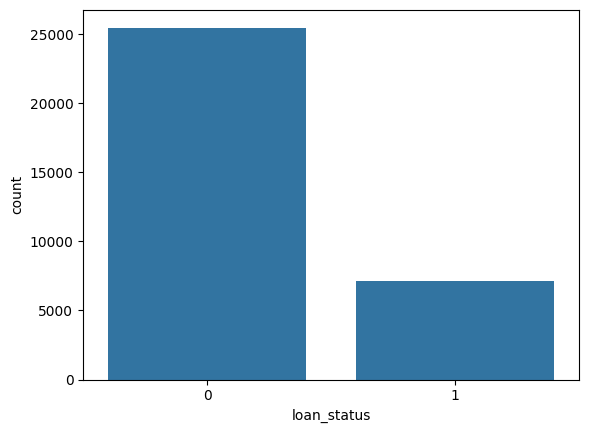

In [ ]:
sns.countplot(x='loan_status', data=df)

In [ ]:
numerical_cols = df.select_dtypes(include=np.number)

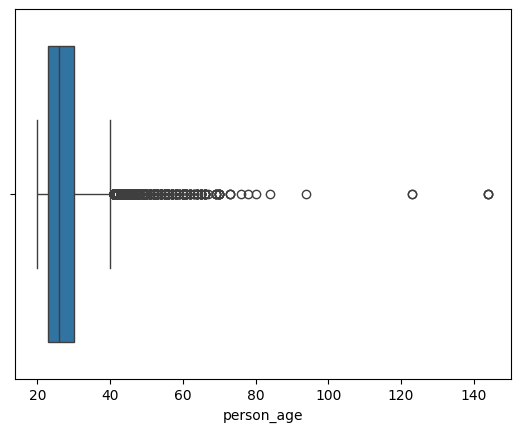

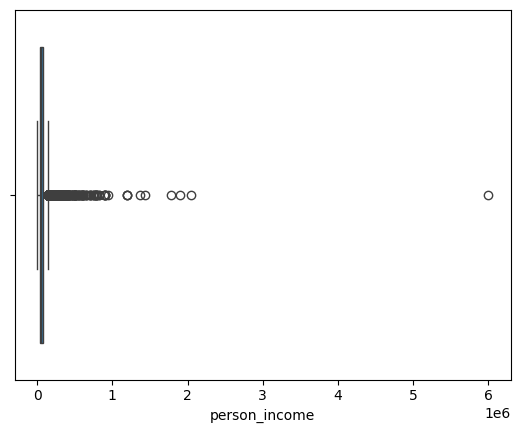

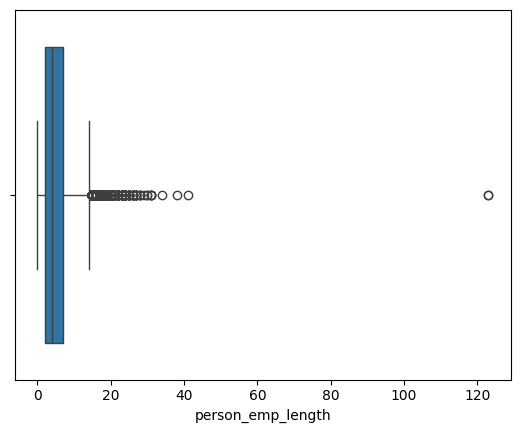

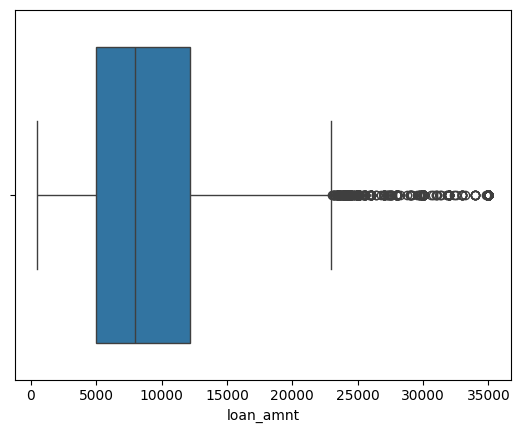

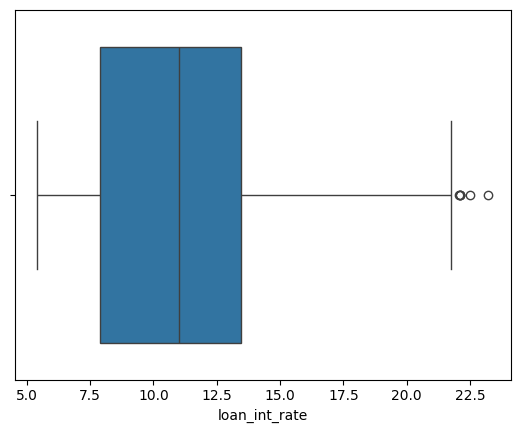

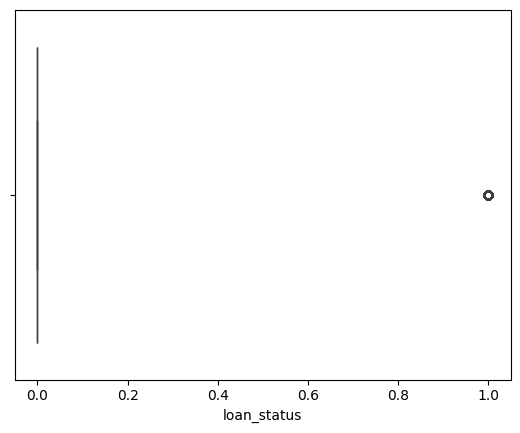

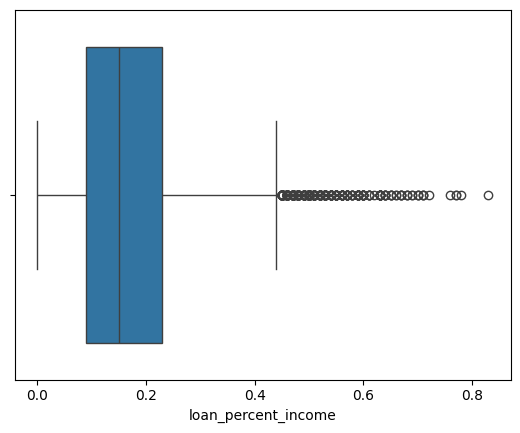

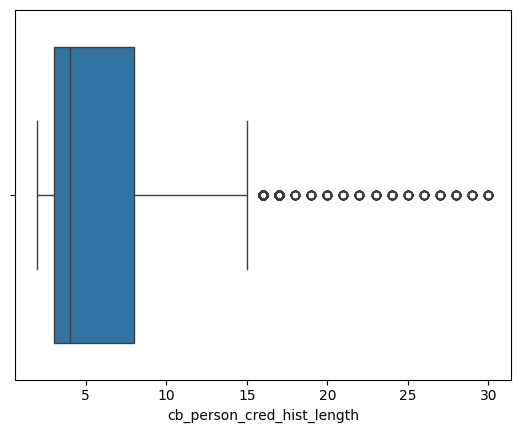

In [ ]:
for i in numerical_cols:
  sns.boxplot(x=df[i])
  plt.show()

Correlation check using HEatmap


<Axes: >

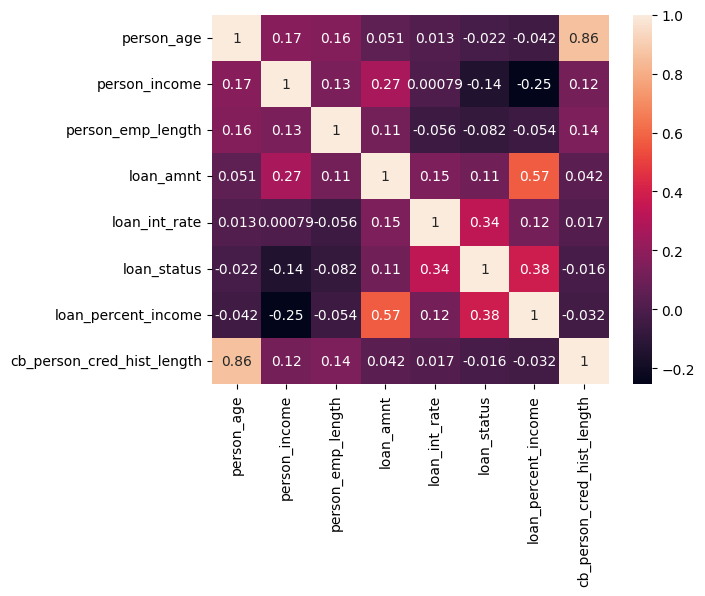

In [ ]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

CLEAN THE DATA

In [ ]:
df_copy = df.copy()
print(f"Original Rows: {df_copy.shape[0]}")

#Remove Duplicate Rows
df_copy.drop_duplicates(inplace=True)


#REmove ages below 18 and above 100
df_copy = df_copy[df_copy['person_age']>=18]
df_copy = df_copy[df_copy['person_age']<=100]

#Remove empployment length greater than age or extreme outliers(>60)

df_copy = df_copy[df_copy['person_emp_length']<=df_copy['person_age']]
df_copy = df_copy[df_copy['person_emp_length']<=60]

df_copy = df_copy[df['loan_amnt']>0]

print(f"Final Rows: {df_copy.shape[0]}")

Original Rows: 32581
Final Rows: 31522


/tmp/ipykernel_4948/1883753573.py:17: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_copy = df_copy[df['loan_amnt']>0]


TRAIN TEST SPLIT

In [ ]:
X = df_copy.drop('loan_status', axis=1)
y = df_copy['loan_status']

X_train, X_test, y_train, y_test = train_test_split(X ,y, test_size=0.2, random_state=42)

separate numerical and categorical columns


In [ ]:
numerical_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

HANDLE CLASS IMBALANCE

using class weights

In [ ]:
y_train.value_counts()

,count
loan_status,
0,19746
1,5471


In [ ]:
neg, pos = np.bincount(y_train)
scale_weight= neg/pos

scale_weight

np.float64(3.6092122098336685)

REGRESSION PIPELINE

In [ ]:
# logistic regression : impute + scale features(numeric),
#                       impute + One-Hot-Encoding

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

numerical_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value="missing")),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]
)

preprocessor column transformer usign pipeline for numerical and catagorical features

In [ ]:
preprocessor_lr = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_cols),
        ('cat', categorical_pipeline, categorical_cols)
    ]
)

In [ ]:
#Preprocessing for XG boost
#pipeline : inpute numerical only  (no scaling) , impute + One-Hot-Encoding

numerical_pipeline_xg = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median'))
    ]
)

categorical_pipeline_xg = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value="missing")),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]
)

preprocessor_xg = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline_xg, numerical_cols),
        ('cat', categorical_pipeline_xg, categorical_cols)
    ]
)

CROSS VALIDARION AND K FOLD

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {'roc_auc', 'accuracy', 'precision', 'recall', 'f1'}

In [ ]:
#Logistic Regression Model

lr_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor_lr),
        ('classifies', LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced"))
    ]
)

In [ ]:
#XG Boost Model
from xgboost import XGBClassifier

xg_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor_xg),
        ('classifier', XGBClassifier(
            n_estimator=300,
            max_depth=5,
            learning_rate=0.1,
            random_state=42,
            scale_pos_weight=scale_weight
          )
        )
    ]
)

In [ ]:
from sklearn.model_selection import cross_validate
import pandas as pd

# Convert scoring set to list to prevent the InvalidParameterError
scoring_list = list(scoring)

for cv_name, pipe in [("Logistic regression", lr_pipeline),
                      ("XGBoost", xg_pipeline)]:
    cv_results = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring_list,
        n_jobs=-1
    )

    print(cv_name)
    print(f"ROC_AUC: {cv_results['test_roc_auc'].mean():.3f}")
    print(f"Accuracy: {cv_results['test_accuracy'].mean():.3f}")
    print(f"Precision: {cv_results['test_precision'].mean():.3f}")
    print(f"Recall: {cv_results['test_recall'].mean():.3f}")
    print(f"F1: {cv_results['test_f1'].mean():.3f}")



Logistic regression
ROC_AUC: 0.874
Accuracy: 0.815
Precision: 0.551
Recall: 0.780
F1: 0.646
XGBoost
ROC_AUC: 0.941
Accuracy: 0.910
Precision: 0.795
Recall: 0.790
F1: 0.793


Baseline Model - Logistic Regression


In [ ]:
baseline_model = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced"))
])

baseline_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

XGBoost Model

In [ ]:
xg_model = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(
            learning_rate=0.1,
            scale_pos_weight=scale_weight,
            random_state=42
          )
        )
])

xg_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

EVALUATION HELPER FUNCTION

In [ ]:
from sklearn.metrics import (
    accuracy_score, classification_report, precision_score, recall_score,
    f1_score, confusion_matrix, precision_recall_curve
)

def evaluate_model(model_name, model, X_test, y_test, threshold=None):
    probabilities = model.predict_proba(X_test)
    class_index = list(model.classes_).index(1)
    y_pred_prob = probabilities[:, class_index]

    if threshold is not None:
        y_pred = (y_pred_prob >= threshold).astype(int)
    else:
        y_pred = model.predict(X_test)

    accuracy_s = accuracy_score(y_test, y_pred)
    precision_s = precision_score(y_test, y_pred, zero_division=0)
    recall_s = recall_score(y_test, y_pred, zero_division=0)
    f1_s = f1_score(y_test, y_pred, zero_division=0)

    print(f"Model: {model_name}")
    print(f"Threshold: {threshold}")
    print(f"Accuracy: {accuracy_s:.3f}")
    print(f"Precision: {precision_s:.3f}")
    print(f"Recall: {recall_s:.3f}")
    print(f"F1: {f1_s:.3f}")

    cm = confusion_matrix(y_test, y_pred)
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'{model_name} - Confusion Matrix')
    plt.show()

    precisions, recalls, _ = precision_recall_curve(y_test, y_pred_prob)
    plt.plot(recalls, precisions)
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f'{model_name} - Precision Recall Curve')
    plt.show()


Model: Baseline Model
Threshold: None
Accuracy: 0.810
Precision: 0.537
Recall: 0.766
F1: 0.631


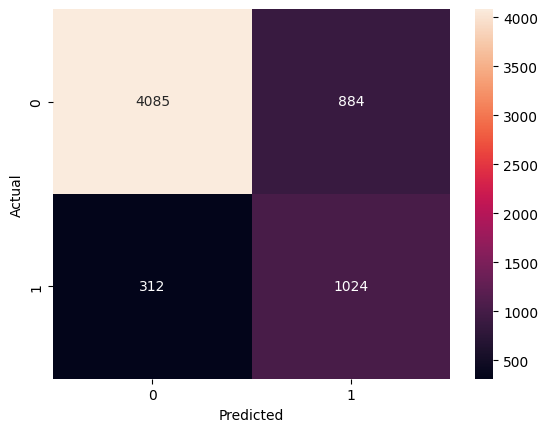

              precision    recall  f1-score   support

           0       0.93      0.82      0.87      4969
           1       0.54      0.77      0.63      1336

    accuracy                           0.81      6305
   macro avg       0.73      0.79      0.75      6305
weighted avg       0.85      0.81      0.82      6305



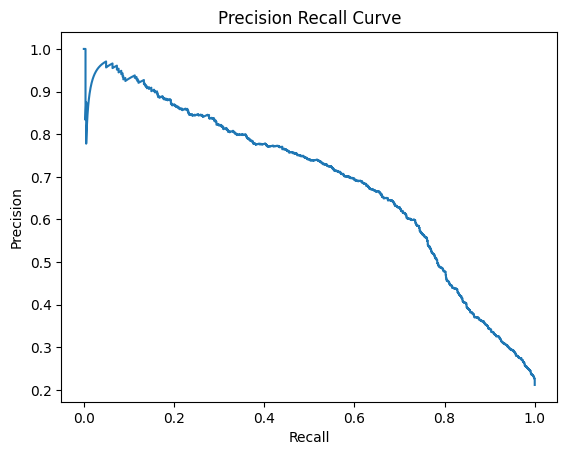

Model: XGBoost Model
Threshold: None
Accuracy: 0.909
Precision: 0.794
Recall: 0.772
F1: 0.783


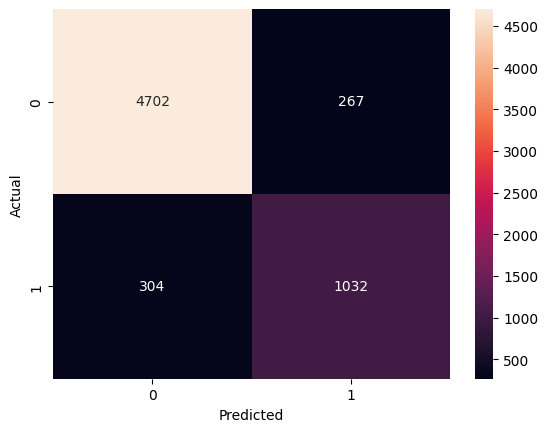

              precision    recall  f1-score   support

           0       0.94      0.95      0.94      4969
           1       0.79      0.77      0.78      1336

    accuracy                           0.91      6305
   macro avg       0.87      0.86      0.86      6305
weighted avg       0.91      0.91      0.91      6305



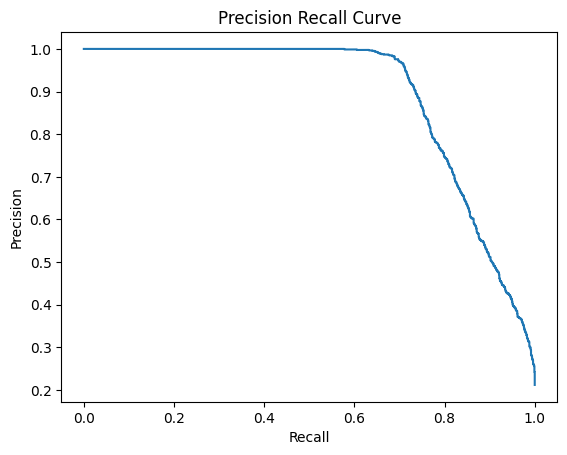

In [ ]:
#Evaluate both models
evaluate_model('Baseline Model', baseline_model, X_test, y_test)
evaluate_model('XGBoost Model', xg_model, X_test, y_test)


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

param_grid = {
    "classifier__n_estimators": randint(150,600),
    "classifier__max_depth": randint(3,9),
    "classifier__learning_rate": uniform(0.01,0.5),
    "classifier__subsample": uniform(0.6,0.4),
    "classifier__colsample_bytree": uniform(0.6,0.4),
    "classifier__min_child_weight": randint(1,10),
    "classifier__gamma":uniform(0, 5)
}


In [ ]:
# Hyperparameter tuning: 150 randomized configurations with 5-fold CV.
# This can take a considerable amount of time and CPU on a laptop.

# Keep validation data separate for threshold selection. The test set remains untouched
# until the final evaluation.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

random_search = RandomizedSearchCV(
    estimator=xg_model,
    param_distributions=param_grid,
    n_iter=150,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1,
    random_state=42,
    refit=True
)

random_search.fit(X_fit, y_fit)
best_model = random_search.best_estimator_

print("Best parameters:", random_search.best_params_)
print("Best cross-validation average precision:", random_search.best_score_)


Fitting 5 folds for each of 10 candidates, totalling 50 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7d1fdabbfe50>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7d1fd9f408d0>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7d1fdabbeb50>},
                   scoring='average_precision', verbose=1)

In [ ]:
# model after hyperparameter tuning

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_

Model: XGBoost
Threshold: 0.9996228218078613
Accuracy: 0.788
Precision: 0.000
Recall: 0.000
F1: 0.000


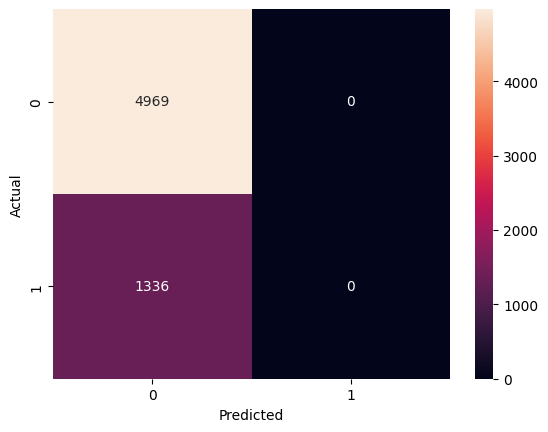

              precision    recall  f1-score   support

           0       0.79      1.00      0.88      4969
           1       0.00      0.00      0.00      1336

    accuracy                           0.79      6305
   macro avg       0.39      0.50      0.44      6305
weighted avg       0.62      0.79      0.69      6305



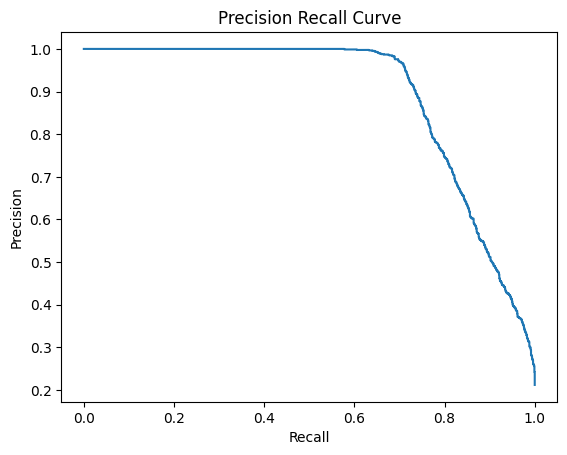

In [ ]:
# Calibrate the tuned model, then select a threshold using validation data only.
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import precision_recall_curve

calibrated_model = CalibratedClassifierCV(
    estimator=best_model,
    method="sigmoid",
    cv=5
)
calibrated_model.fit(X_fit, y_fit)

# Positive-class probability on the held-out validation set
class_index = list(calibrated_model.classes_).index(1)
val_prob = calibrated_model.predict_proba(X_val)[:, class_index]

precisions, recalls, thresholds = precision_recall_curve(y_val, val_prob)

# precision and recall contain one extra endpoint compared with thresholds
f1_scores = (
    2 * precisions[:-1] * recalls[:-1]
    / (precisions[:-1] + recalls[:-1] + 1e-9)
)

if len(thresholds) == 0:
    raise ValueError("No thresholds were produced. Check the validation labels and model probabilities.")

best_index = int(f1_scores.argmax())
best_threshold = float(thresholds[best_index])

print(f"Best validation threshold: {best_threshold:.6f}")
print(f"Validation precision at threshold: {precisions[best_index]:.4f}")
print(f"Validation recall at threshold: {recalls[best_index]:.4f}")
print(f"Validation F1 at threshold: {f1_scores[best_index]:.4f}")

# Final evaluation on the untouched test set
evaluate_model("Calibrated tuned XGBoost", calibrated_model, X_test, y_test, best_threshold)


PROBABILITY CALIBRATION

[0.00985843 0.0141443  0.00289946 ... 0.0603302  0.0129884  0.98845357]
[0.01000551 0.01020149 0.00971532 ... 0.0140233  0.01011355 0.95647088]


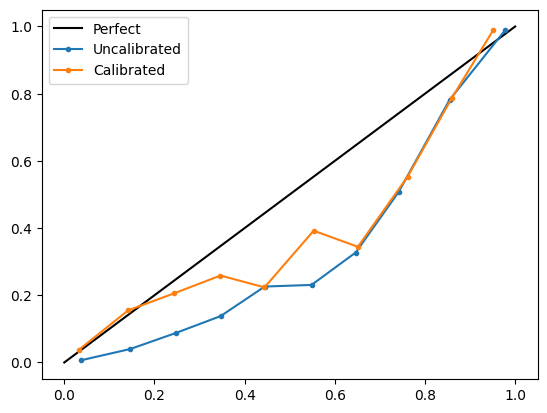

In [ ]:
# Inspect calibration on the held-out test set. This cell is diagnostic only;
# the test set is not used to select or modify the threshold.
from sklearn.calibration import calibration_curve

class_index = list(calibrated_model.classes_).index(1)
uncalibrated = best_model.predict_proba(X_test)[:, list(best_model.classes_).index(1)]
calibrated = calibrated_model.predict_proba(X_test)[:, class_index]

actual_uncal, predicted_uncal = calibration_curve(
    y_test, uncalibrated, n_bins=10, strategy="quantile"
)
actual_cal, predicted_cal = calibration_curve(
    y_test, calibrated, n_bins=10, strategy="quantile"
)

plt.figure(figsize=(7, 6))
plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
plt.plot(predicted_uncal, actual_uncal, marker=".", label="Tuned model (uncalibrated)")
plt.plot(predicted_cal, actual_cal, marker=".", label="Calibrated tuned model")
plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positives")
plt.title("Calibration Curve - Test Set")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


SHAP tells the contribution of each feature

In [ ]:
#install shap
!pip install shap
import shap

In [ ]:
# Explain the tuned XGBoost pipeline (the base estimator used for calibration).
xgb_classifier = best_model.named_steps['classifier']

X_test_transformed = best_model.named_steps['preprocessor'].transform(X_test)
feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()

X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)


In [ ]:
# create SHAP explainer built for tree-based model
explainer = shap.TreeExplainer(xgb_classifier)

In [ ]:
# calculate shap values for every row in the test set
shap_values = explainer.shap_values(X_test_df)
shap_values

array([[-7.7432315e-03, -7.5094008e-01, -1.2367868e-01, ...,
        -1.0665227e-02, -8.8718330e-04,  0.0000000e+00],
       [ 3.5132736e-02, -8.9686233e-01, -1.0950860e-01, ...,
        -1.1027072e-02, -6.7942322e-04,  0.0000000e+00],
       [ 3.2211039e-02, -1.6605960e-01, -8.8492788e-02, ...,
        -8.2157142e-03, -4.5424993e-03,  0.0000000e+00],
       ...,
       [ 3.1050751e-02, -9.8210394e-01, -1.2644650e-01, ...,
        -1.0403723e-02, -1.4258506e-03,  0.0000000e+00],
       [-5.3404653e-03, -8.5086465e-01,  5.8639098e-02, ...,
        -1.0982760e-02,  8.5223338e-04,  0.0000000e+00],
       [ 8.4826246e-02,  1.5625656e-01,  7.0657499e-02, ...,
        -9.0896273e-03, -1.5567085e-03,  0.0000000e+00]],
      shape=(6305, 26), dtype=float32)

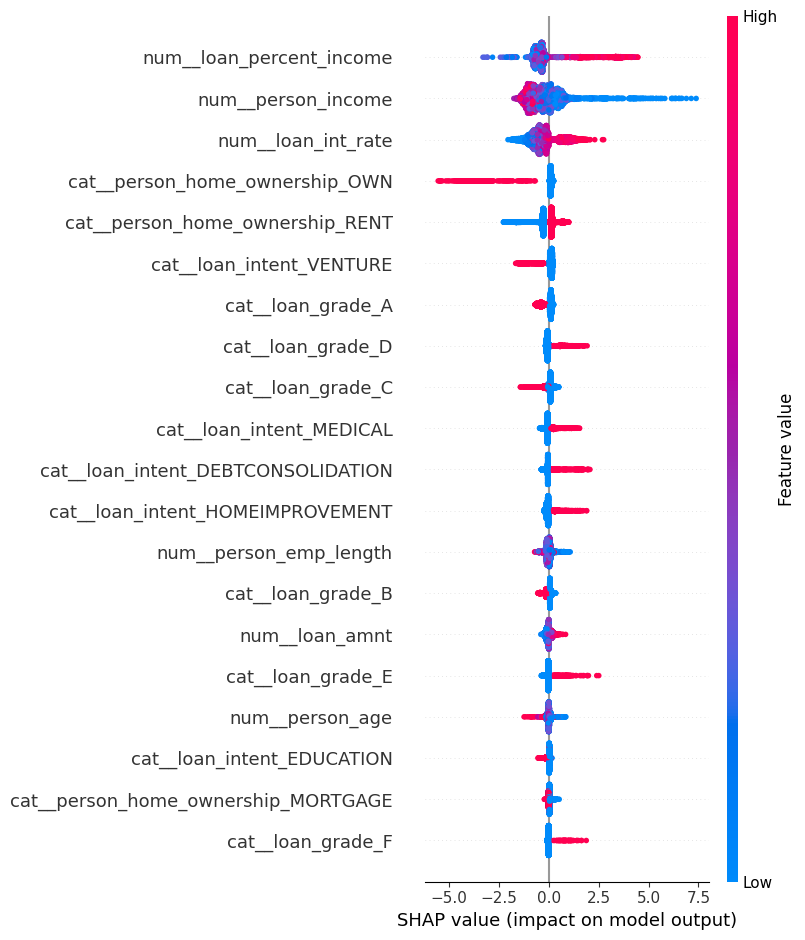

In [ ]:
# GLOBAL EXPLAINATION
shap.summary_plot(shap_values, X_test_df)


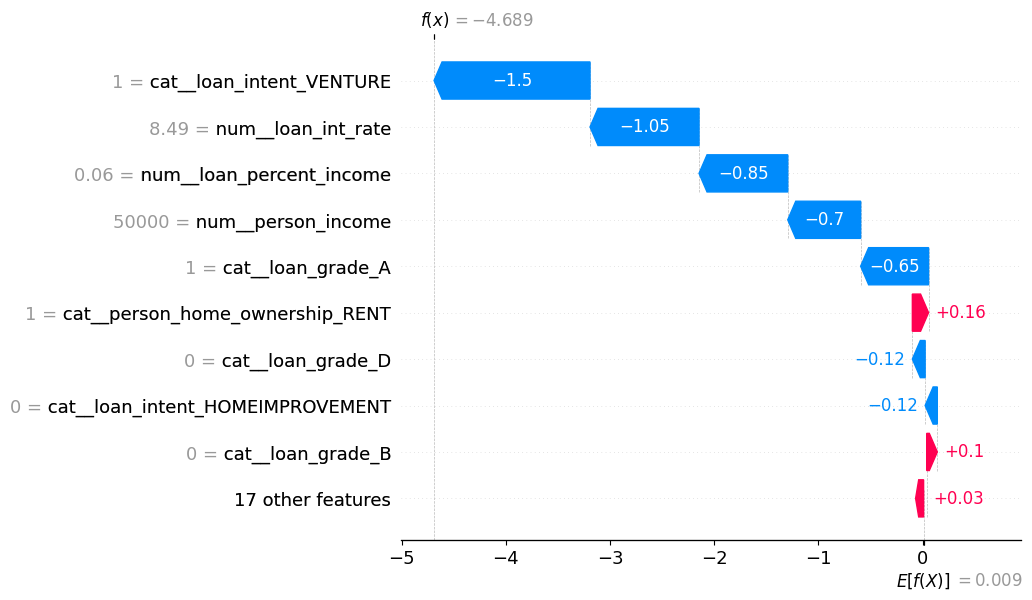

In [ ]:
# LOCAL EXPLAINATION

#1 pick one row to explain
row_index = 5

#2 draw a waterfall plot for each feature contribution
shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,
        data = X_test_df.iloc[row_index],
        feature_names = X_test_df.columns
    )
)

FALSE POSITIVES AND FALSE NEGATIVES

In [ ]:
y_pred = random_search.predict(X_test)

#create a dataframe to easily compare the actual and pred values
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred
result_df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
8400,24,69996,RENT,5.0,VENTURE,A,7500,7.49,0.11,N,2,0,0
5698,23,150000,RENT,3.0,VENTURE,B,5000,10.65,0.03,N,2,0,0
15233,23,24000,OWN,5.0,EDUCATION,B,7000,11.86,0.29,N,4,0,0
28674,27,120000,MORTGAGE,11.0,PERSONAL,A,7000,6.76,0.06,N,7,0,0
26437,30,90000,MORTGAGE,7.0,DEBTCONSOLIDATION,A,4800,8.90,0.05,N,5,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
17341,24,75000,RENT,6.0,HOMEIMPROVEMENT,B,15000,11.71,0.20,N,4,0,0
13239,24,90000,MORTGAGE,0.0,DEBTCONSOLIDATION,C,8000,12.99,0.09,N,2,0,0
26469,33,103000,MORTGAGE,5.0,EDUCATION,A,24000,7.49,0.23,N,10,0,0
26680,32,110000,MORTGAGE,2.0,VENTURE,B,5600,10.74,0.05,N,7,0,0


In [ ]:
# false positive : model predicted = 1 but actual = 0
false_positive = result_df[(result_df['actual'] == 0) & (result_df['predicted'] == 1)]
print(f"False Positive: {len(false_positive)}")


# false negative : model predicted = 0 but actual = 1
false_negative = result_df[(result_df['actual'] == 1) & (result_df['predicted'] == 0)]
print(f"False Negative: {len(false_negative)}")


False Positive: 357
False Negative: 256


SAVING THE FINAL BEST MODEL (calibrated model)

In [ ]:
import joblib

joblib.dump(calibrated_model, "credit_risk_model.pkl")
print("Saved calibrated tuned model to credit_risk_model.pkl")


['credit_risk_model.pkl']

In [ ]:
joblib.dump(float(best_threshold), "best_threshold.pkl")
print(f"Saved validation-selected threshold ({best_threshold:.6f}) to best_threshold.pkl")


['best_threshold.pkl']